# Assignment 3 — Neural Q-Learning

This notebook reuses the stochastic shortest-path MDP from Assignment 2 and replaces the tabular Q table with a feedforward neural network. The learner trains **only from sampled transitions**. The transition probabilities are used only inside the environment to sample the next state.

Training uses experience replay with a **32-transition random mini-batch every 8 completed episodes**. Since every episode in this MDP contains four transitions, this corresponds to approximately one optimizer update per 32 newly collected transitions.

## 1. Imports and reproducibility

In [1]:
import platform
import random
import time
from collections import deque
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim

OUTPUT_DIR = Path("neural_q_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Device support: CUDA =", torch.cuda.is_available())

Python: 3.12.3
PyTorch: 2.15.0+cpu
NumPy: 2.5.4
Pandas: 3.0.6
Device support: CUDA = False


## 2. Assignment 2 MDP

The environment is unchanged: states `a` through `h`, start state `a`, terminal state `h`, discount factor $\gamma=1$, stochastic 0.8/0.2 branches at `a`, `b`, and `c`, and deterministic transitions thereafter. Costs are minimized.

In [2]:
data = [
    ['a','Ab','b',0.8,2], ['a','Ab','c',0.2,2],
    ['a','Ac','c',0.8,2], ['a','Ac','b',0.2,2],
    ['b','Ad','d',0.8,3], ['b','Ad','e',0.2,2],
    ['b','Ae','e',0.8,2], ['b','Ae','d',0.2,3],
    ['c','Ae','e',0.8,5], ['c','Ae','f',0.2,4],
    ['c','Af','f',0.8,4], ['c','Af','e',0.2,5],
    ['d','Ag','g',1.0,3], ['e','Ag','g',1.0,3],
    ['f','Ag','g',1.0,2], ['g','Ah','h',1.0,1],
]
columns = ['S','A','S_next','P','C']
df = pd.DataFrame(data, columns=columns)

STATES = ['a','b','c','d','e','f','g','h']
ACTIONS = ['Ab','Ac','Ad','Ae','Af','Ag','Ah']
START_STATE = 'a'
TERMINAL_STATE = 'h'

state_to_idx = {s:i for i,s in enumerate(STATES)}
action_to_idx = {a:i for i,a in enumerate(ACTIONS)}
feasible_actions = {
    s: df.loc[df.S.eq(s), 'A'].unique().tolist()
    for s in STATES[:-1]
}
feasible_action_idx = {
    s: [action_to_idx[a] for a in acts]
    for s, acts in feasible_actions.items()
}

display(df)
print("Feasible actions:", feasible_actions)

,S,A,S_next,P,C
0,a,Ab,b,0.8,2
1,a,Ab,c,0.2,2
2,a,Ac,c,0.8,2
3,a,Ac,b,0.2,2
4,b,Ad,d,0.8,3
5,b,Ad,e,0.2,2
6,b,Ae,e,0.8,2
7,b,Ae,d,0.2,3
8,c,Ae,e,0.8,5
9,c,Ae,f,0.2,4


Feasible actions: {'a': ['Ab', 'Ac'], 'b': ['Ad', 'Ae'], 'c': ['Ae', 'Af'], 'd': ['Ag'], 'e': ['Ag'], 'f': ['Ag'], 'g': ['Ah']}


### Sample-only environment
`env_step` samples a transition and returns only the observed next state, cost, and terminal flag. The neural learner never receives the transition probabilities as training targets.

In [3]:
def env_step(current_state, current_action, rng):
    rows = df[(df.S == current_state) & (df.A == current_action)]
    probs = rows.P.to_numpy(dtype=float)
    choice = rng.choice(len(rows), p=probs / probs.sum())
    row = rows.iloc[choice]
    next_state = row.S_next
    cost = float(row.C)
    done = (next_state == TERMINAL_STATE)
    return next_state, cost, done

# Sanity check using an RNG that is unrelated to training.
check_rng = np.random.default_rng(12345)
N_CHECK = 10_000
p_b = np.mean([env_step('a', 'Ab', check_rng)[0] == 'b' for _ in range(N_CHECK)])
p_c = np.mean([env_step('a', 'Ac', check_rng)[0] == 'c' for _ in range(N_CHECK)])
print(f"Empirical P(b | a, Ab) = {p_b:.3f}; expected 0.8")
print(f"Empirical P(c | a, Ac) = {p_c:.3f}; expected 0.8")

Empirical P(b | a, Ab) = 0.806; expected 0.8
Empirical P(c | a, Ac) = 0.796; expected 0.8


## 3. Neural Q-function

- **Input:** 8-dimensional one-hot state vector.
- **Hidden layers:** 32 ReLU units, then 32 ReLU units.
- **Output:** 7 linear Q-values corresponding to `[Ab, Ac, Ad, Ae, Af, Ag, Ah]`.
- **Invalid actions:** explicitly masked before greedy action selection and before computing the target-network bootstrap minimum.
- **Cost convention:** smaller Q-values are better.

Parameter count:

$$(8\times32+32)+(32\times32+32)+(32\times7+7)=1575.$$

In [4]:
class QNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(len(STATES), 32),
            nn.ReLU(),
            nn.Linear(32, 32),
            nn.ReLU(),
            nn.Linear(32, len(ACTIONS)),
        )

    def forward(self, x):
        return self.net(x)


def encode_states(states, device):
    indices = torch.tensor(
        [state_to_idx[s] for s in states], dtype=torch.long, device=device
    )
    return torch.nn.functional.one_hot(indices, num_classes=len(STATES)).float()


test_net = QNetwork()
NUM_PARAMS = sum(p.numel() for p in test_net.parameters() if p.requires_grad)
print("Trainable parameters:", NUM_PARAMS)

Trainable parameters: 1575


## 4. Hyperparameters

The replay buffer receives every sampled transition. Optimization is intentionally performed only **once every 8 episodes**, using a fresh random mini-batch of 32 transitions from the full replay buffer. This reduces unnecessary optimizer overhead while retaining experience replay and mini-batch learning.

In [ ]:
GAMMA = 1.0
EPISODES = 5000
SEEDS = [0, 1, 2, 3, 4]

# EPS is epsilon for epsilon-greedy exploration
EPS_START = 1.00
EPS_END = 0.05
EPS_DECAY_EPISODES = 4000

REPLAY_CAPACITY = 10000
REPLAY_WARMUP = 200
BATCH_SIZE = 32
OPTIMIZE_EVERY_EPISODES = 8

LEARNING_RATE = 1e-3
TARGET_UPDATE_STEPS = 100       # measured in optimizer/learning steps
EVAL_EPISODES = 1000
PROGRESS_EVERY = 500

# This problem is tiny; CPU is sufficient and avoids GPU setup/transfer overhead.
DEVICE = torch.device('cpu')
print("Training device:", DEVICE)


def epsilon_by_episode(ep):
    # ep is zero-based. Linear schedule reaches EPS_END at episode 4000.
    frac = min(ep / EPS_DECAY_EPISODES, 1.0)
    return EPS_START + frac * (EPS_END - EPS_START)


hyperparams = pd.DataFrame([
    ['State encoding', '8-D one-hot'],
    ['Network', '8 -> 32 ReLU -> 32 ReLU -> 7 linear'],
    ['Trainable parameters', NUM_PARAMS],
    ['Optimizer', 'Adam'],
    ['Learning rate', LEARNING_RATE],
    ['Loss', 'Mean squared error'],
    ['Discount factor', GAMMA],
    ['Replay capacity', REPLAY_CAPACITY],
    ['Replay warm-up', REPLAY_WARMUP],
    ['Batch size', BATCH_SIZE],
    ['Optimization frequency', f'Every {OPTIMIZE_EVERY_EPISODES} episodes'],
    ['Target update', f'Hard copy every {TARGET_UPDATE_STEPS} learning steps'],
    ['Episodes / seed', EPISODES],
    ['Seeds', str(SEEDS)],
    ['Epsilon schedule', 'Linear 1.00 -> 0.05 through episode 4000; then 0.05'],
    ['Evaluation episodes / seed', EVAL_EPISODES],
], columns=['Hyperparameter', 'Value'])
display(hyperparams)
hyperparams.to_csv(OUTPUT_DIR / 'hyperparameters.csv', index=False)

Training device: cpu


,Hyperparameter,Value
0,State encoding,8-D one-hot
1,Network,8 -> 32 ReLU -> 32 ReLU -> 7 linear
2,Trainable parameters,1575
3,Optimizer,Adam
4,Learning rate,0.001
5,Loss,Mean squared error
6,Discount factor,1.0
7,Replay capacity,10000
8,Replay warm-up,200
9,Batch size,32


## 5. Action selection and one replay optimization step

In [6]:
def choose_action(net, state, epsilon, rng):
    """Epsilon-greedy cost-minimizing action with uniform random exact tie-breaking."""
    valid_actions = feasible_actions[state]

    if rng.random() < epsilon:
        return valid_actions[int(rng.integers(len(valid_actions)))]

    with torch.no_grad():
        q = net(encode_states([state], DEVICE))[0].cpu().numpy()

    valid_idx = np.asarray(feasible_action_idx[state], dtype=int)
    valid_q = q[valid_idx]
    best_q = np.min(valid_q)
    tie_idx = valid_idx[np.isclose(valid_q, best_q, rtol=1e-7, atol=1e-9)]
    chosen_idx = int(tie_idx[int(rng.integers(len(tie_idx)))])
    return ACTIONS[chosen_idx]


def optimize_from_replay(online, target, optimizer, criterion, replay, rng):
    """Sample one random 32-transition mini-batch and perform one gradient update."""
    batch_ids = rng.choice(len(replay), size=BATCH_SIZE, replace=False)
    batch = [replay[int(i)] for i in batch_ids]
    states_b, actions_b, costs_b, next_states_b, dones_b = zip(*batch)

    states_t = encode_states(states_b, DEVICE)
    action_idx_t = torch.tensor(
        [action_to_idx[a] for a in actions_b], dtype=torch.long, device=DEVICE
    ).unsqueeze(1)
    costs_t = torch.tensor(costs_b, dtype=torch.float32, device=DEVICE)
    dones_t = torch.tensor(dones_b, dtype=torch.bool, device=DEVICE)

    # Q_online(s,a) for the sampled actions.
    q_pred = online(states_t).gather(1, action_idx_t).squeeze(1)

    # Target y = c for terminal transitions; otherwise c + gamma min_a' Q_target(s',a').
    with torch.no_grad():
        bootstrap = torch.zeros(BATCH_SIZE, dtype=torch.float32, device=DEVICE)
        nonterminal_indices = torch.where(~dones_t)[0]

        if len(nonterminal_indices) > 0:
            nt_states = [next_states_b[int(i)] for i in nonterminal_indices.cpu().numpy()]
            q_next = target(encode_states(nt_states, DEVICE))

            # Explicit feasible-action masking: invalid actions receive +infinity
            # because this is a cost-minimization problem.
            masked_next = torch.full_like(q_next, float('inf'))
            for row, s_next in enumerate(nt_states):
                valid_idx = feasible_action_idx[s_next]
                masked_next[row, valid_idx] = q_next[row, valid_idx]

            min_next = masked_next.min(dim=1).values
            bootstrap[nonterminal_indices] = min_next

        y = costs_t + GAMMA * bootstrap

    loss = criterion(q_pred, y)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    return float(loss.item())

## 6. Train one independent seed

For every seed, the online network, target network, optimizer, replay buffer, exploration state, and random-number generators are recreated. Episode costs and learning losses are saved to CSV as training proceeds. A checkpoint is saved at the end of each seed.

In [7]:
def train_seed(seed):
    # Independent random state for this training run.
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)

    online = QNetwork().to(DEVICE)
    target = QNetwork().to(DEVICE)
    target.load_state_dict(online.state_dict())
    target.eval()

    optimizer = optim.Adam(online.parameters(), lr=LEARNING_RATE)
    criterion = nn.MSELoss()
    replay = deque(maxlen=REPLAY_CAPACITY)

    episode_costs = []
    losses = []
    loss_episodes = []
    learning_steps = 0
    start_time = time.perf_counter()

    for ep in range(EPISODES):
        epsilon = epsilon_by_episode(ep)
        state = START_STATE
        total_cost = 0.0

        # Every episode reaches h in four transitions for this acyclic MDP.
        while state != TERMINAL_STATE:
            action = choose_action(online, state, epsilon, rng)
            next_state, cost, done = env_step(state, action, rng)
            replay.append((state, action, cost, next_state, done))
            total_cost += cost
            state = next_state

        episode_costs.append(total_cost)

        # One random 32-transition replay update every 8 completed episodes.
        if ((ep + 1) % OPTIMIZE_EVERY_EPISODES == 0
                and len(replay) >= REPLAY_WARMUP):
            loss = optimize_from_replay(
                online, target, optimizer, criterion, replay, rng
            )
            losses.append(loss)
            loss_episodes.append(ep + 1)
            learning_steps += 1

            if learning_steps % TARGET_UPDATE_STEPS == 0:
                target.load_state_dict(online.state_dict())

        if (ep + 1) % PROGRESS_EVERY == 0 or ep == 0:
            elapsed = time.perf_counter() - start_time
            recent = np.mean(episode_costs[-100:])
            print(
                f"Seed {seed} | episode {ep+1:4d}/{EPISODES} | "
                f"eps={epsilon:.3f} | replay={len(replay):5d} | "
                f"updates={learning_steps:3d} | recent100={recent:.3f} | "
                f"elapsed={elapsed:.1f}s"
            )

    elapsed = time.perf_counter() - start_time

    # Persist raw histories so plots can be regenerated without retraining.
    pd.DataFrame({
        'episode': np.arange(1, EPISODES + 1),
        'episode_cost': episode_costs,
        'epsilon': [epsilon_by_episode(ep) for ep in range(EPISODES)],
    }).to_csv(OUTPUT_DIR / f'seed{seed}_episode_costs.csv', index=False)

    pd.DataFrame({
        'learning_step': np.arange(1, len(losses) + 1),
        'episode': loss_episodes,
        'mse_loss': losses,
    }).to_csv(OUTPUT_DIR / f'seed{seed}_losses.csv', index=False)

    torch.save({
        'seed': seed,
        'model_state_dict': online.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'learning_steps': learning_steps,
        'elapsed_seconds': elapsed,
    }, OUTPUT_DIR / f'seed{seed}_model.pt')

    print(
        f"Seed {seed} complete: {elapsed:.1f}s, "
        f"{learning_steps} optimizer steps, {len(replay)} transitions retained."
    )
    return online, np.asarray(episode_costs), np.asarray(losses), np.asarray(loss_episodes), elapsed

## 7. Train all five independent seeds

In [8]:
trained = {}
all_start = time.perf_counter()

for seed in SEEDS:
    print("\n" + "=" * 72)
    print(f"Training seed {seed}")
    print("=" * 72)
    net, costs, losses, loss_episodes, elapsed = train_seed(seed)
    trained[seed] = {
        'net': net,
        'costs': costs,
        'losses': losses,
        'loss_episodes': loss_episodes,
        'elapsed_seconds': elapsed,
    }

print(f"\nAll five seeds complete in {time.perf_counter() - all_start:.1f} s.")


Training seed 0
Seed 0 | episode    1/5000 | eps=1.000 | replay=    4 | updates=  0 | recent100=9.000 | elapsed=0.0s
Seed 0 | episode  500/5000 | eps=0.881 | replay= 2000 | updates= 56 | recent100=9.140 | elapsed=7.0s
Seed 0 | episode 1000/5000 | eps=0.763 | replay= 4000 | updates=119 | recent100=9.420 | elapsed=14.6s
Seed 0 | episode 1500/5000 | eps=0.644 | replay= 6000 | updates=181 | recent100=9.370 | elapsed=21.9s
Seed 0 | episode 2000/5000 | eps=0.525 | replay= 8000 | updates=244 | recent100=8.930 | elapsed=30.0s
Seed 0 | episode 2500/5000 | eps=0.406 | replay=10000 | updates=306 | recent100=8.670 | elapsed=37.8s
Seed 0 | episode 3000/5000 | eps=0.288 | replay=10000 | updates=369 | recent100=8.750 | elapsed=46.4s
Seed 0 | episode 3500/5000 | eps=0.169 | replay=10000 | updates=431 | recent100=8.680 | elapsed=55.5s
Seed 0 | episode 4000/5000 | eps=0.050 | replay=10000 | updates=494 | recent100=8.570 | elapsed=63.9s
Seed 0 | episode 4500/5000 | eps=0.050 | replay=10000 | updates=556

## 8. Seed 4 required learning curves

The first figure shows individual episode cost and the required 100-episode rolling mean. The second shows MSE training loss versus learning step with a readable rolling average. Raw data were already saved to CSV.

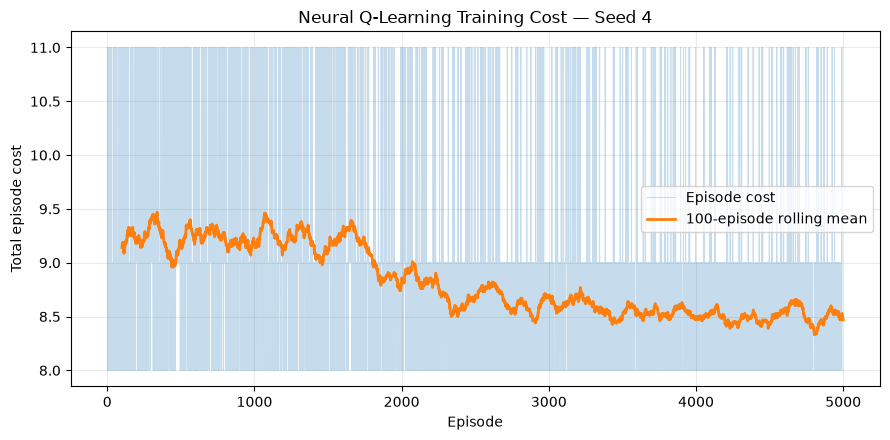

In [9]:
seed4_costs = trained[4]['costs']
rolling_cost = pd.Series(seed4_costs).rolling(100).mean()

plt.figure(figsize=(9, 4.5))
plt.plot(np.arange(1, EPISODES + 1), seed4_costs,
         alpha=0.25, linewidth=0.7, label='Episode cost')
plt.plot(np.arange(1, EPISODES + 1), rolling_cost,
         linewidth=2.0, label='100-episode rolling mean')
plt.xlabel('Episode')
plt.ylabel('Total episode cost')
plt.title('Neural Q-Learning Training Cost — Seed 4')
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'seed4_neuralq_cost.png', dpi=200)
plt.show()

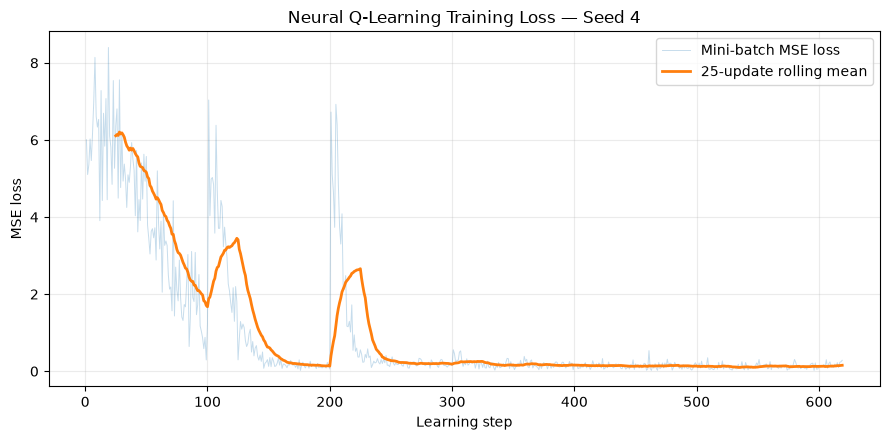

In [10]:
seed4_losses = trained[4]['losses']
seed4_loss_eps = trained[4]['loss_episodes']
LOSS_ROLLING_WINDOW = 25
rolling_loss = pd.Series(seed4_losses).rolling(LOSS_ROLLING_WINDOW).mean()

plt.figure(figsize=(9, 4.5))
plt.plot(np.arange(1, len(seed4_losses) + 1), seed4_losses,
         alpha=0.25, linewidth=0.7, label='Mini-batch MSE loss')
plt.plot(np.arange(1, len(seed4_losses) + 1), rolling_loss,
         linewidth=2.0, label=f'{LOSS_ROLLING_WINDOW}-update rolling mean')
plt.xlabel('Learning step')
plt.ylabel('MSE loss')
plt.title('Neural Q-Learning Training Loss — Seed 4')
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'seed4_neuralq_loss.png', dpi=200)
plt.show()

## 9. Learned greedy policy and nominal greedy path

A greedy action is reported at **every nonterminal state** for every seed. Exact Q-value ties are resolved uniformly at random. The nominal path follows the intended (highest-probability) transition after each selected action.

In [11]:
def greedy_policy(net, rng):
    return {
        s: choose_action(net, s, epsilon=0.0, rng=rng)
        for s in STATES[:-1]
    }


def nominal_next_state(state, action):
    rows = df[(df.S == state) & (df.A == action)]
    return rows.loc[rows.P.idxmax(), 'S_next']


def nominal_path(policy):
    path = [START_STATE]
    s = START_STATE
    while s != TERMINAL_STATE:
        s = nominal_next_state(s, policy[s])
        path.append(s)
    return ' -> '.join(path)


policies = {}
policy_rows = []
for seed in SEEDS:
    # Separate RNG only for uniform tie-breaking during policy extraction.
    policy_rng = np.random.default_rng(50_000 + seed)
    policy = greedy_policy(trained[seed]['net'], policy_rng)
    policies[seed] = policy
    row = {'seed': seed, **policy, 'nominal_path': nominal_path(policy)}
    policy_rows.append(row)

policy_table = pd.DataFrame(policy_rows)
display(policy_table)
policy_table.to_csv(OUTPUT_DIR / 'neuralq_five_seed_policies.csv', index=False)

,seed,a,b,c,d,e,f,g,nominal_path
0,0,Ab,Ae,Af,Ag,Ag,Ag,Ah,a -> b -> e -> g -> h
1,1,Ab,Ae,Af,Ag,Ag,Ag,Ah,a -> b -> e -> g -> h
2,2,Ab,Ae,Af,Ag,Ag,Ag,Ah,a -> b -> e -> g -> h
3,3,Ab,Ae,Af,Ag,Ag,Ag,Ah,a -> b -> e -> g -> h
4,4,Ab,Ae,Af,Ag,Ag,Ag,Ah,a -> b -> e -> g -> h


## 10. Required 1,000-episode stochastic evaluation

Each trained neural policy is evaluated for 1,000 stochastic episodes with exploration turned off. Evaluation randomness uses a new RNG (`100000 + seed`) and is therefore separate from training. We report mean total cost, standard deviation, minimum, maximum, and percentage of episodes reaching `h`.

In [ ]:
def evaluate_policy(net, seed, n_episodes=EVAL_EPISODES):
    rng = np.random.default_rng(100000 + seed)
    episode_costs = []
    reached_h = 0

    for _ in range(n_episodes):
        state = START_STATE
        total_cost = 0.0
        steps = 0

        while state != TERMINAL_STATE and steps < 100:
            action = choose_action(net, state, epsilon=0.0, rng=rng)
            state, cost, done = env_step(state, action, rng)
            total_cost += cost
            steps += 1
            if done:
                reached_h += 1
                break

        episode_costs.append(total_cost)

    episode_costs = np.asarray(episode_costs, dtype=float)
    return episode_costs, {
        'mean_cost': episode_costs.mean(),
        'std_cost': episode_costs.std(ddof=1),
        'min_cost': episode_costs.min(),
        'max_cost': episode_costs.max(),
        'reach_h_pct': 100.0 * reached_h / n_episodes,
    }


eval_rows = []
for seed in SEEDS:
    eval_costs, stats = evaluate_policy(trained[seed]['net'], seed)
    pd.DataFrame({
        'evaluation_episode': np.arange(1, EVAL_EPISODES + 1),
        'total_cost': eval_costs,
    }).to_csv(OUTPUT_DIR / f'seed{seed}_evaluation_costs.csv', index=False)

    eval_rows.append({
        'seed': seed,
        **stats,
        'nominal_path': nominal_path(policies[seed]),
    })

eval_table = pd.DataFrame(eval_rows)
display(eval_table)
eval_table.to_csv(OUTPUT_DIR / 'neuralq_five_seed_evaluation.csv', index=False)

,seed,mean_cost,std_cost,min_cost,max_cost,reach_h_pct,nominal_path
0,0,8.464,0.737053,8.0,11.0,100.0,a -> b -> e -> g -> h
1,1,8.377,0.615833,8.0,11.0,100.0,a -> b -> e -> g -> h
2,2,8.416,0.682209,8.0,11.0,100.0,a -> b -> e -> g -> h
3,3,8.448,0.723754,8.0,11.0,100.0,a -> b -> e -> g -> h
4,4,8.449,0.744280,8.0,11.0,100.0,a -> b -> e -> g -> h


## 11. Neural vs. tabular Q-learning comparison

Use the numerical results generated above together with your Assignment 2 results in the report.

- **Representation:** tabular Q-learning stores an independent value for each feasible state-action pair; neural Q-learning uses a 1575-parameter function approximator shared across states/actions.
- **Model access:** both learners train from sampled transitions only. The environment uses the transition model only to generate samples.
- **Sampling:** neural Q-learning additionally stores transitions and randomly reuses them through experience replay.
- **Exploration:** both use epsilon-greedy exploration and prefer smaller Q-values because the objective is cost minimization.
- **Stability:** tabular updates affect one table entry directly. Neural updates can alter several predictions simultaneously, motivating experience replay and a separate target network.
- **Reproducibility:** both are stochastic; the neural method adds random initialization and mini-batch sampling, so five independent seeds are particularly useful.
- **Hyperparameter sensitivity:** the neural method adds architecture, optimizer, learning rate, replay settings, target-update frequency, and optimization frequency.
- **Benefit on this problem:** because there are only eight states and very few feasible state-action pairs, a neural approximation is not expected to be more efficient than a table. Its value here is demonstrating the function-approximation machinery needed for larger or continuous state spaces.

## 12. Output files and README notes

After one complete run, `neural_q_outputs/` contains:

- `seed0...seed4_episode_costs.csv` — all 5000 raw episode costs and epsilon values.
- `seed0...seed4_losses.csv` — every mini-batch loss and the episode at which the update occurred.
- `seed0...seed4_model.pt` — trained PyTorch checkpoints.
- `seed0...seed4_evaluation_costs.csv` — all 1000 evaluation episode costs.
- `neuralq_five_seed_policies.csv` — greedy action at every nonterminal state and nominal path.
- `neuralq_five_seed_evaluation.csv` — required five-seed evaluation statistics.
- `hyperparameters.csv` — compact hyperparameter table.
- `seed4_neuralq_cost.png` and `seed4_neuralq_loss.png` — required learning curves.
